# Stability thresholds and cost amplification in aqueous organic flow batteries

## 0. Scope and sources

Run the notebook from the repository root. The two CSV inputs are in `data/` and are also embedded for standalone use. The three figures are written to `figures/`.

- [Yang et al. (2021)](https://doi.org/10.3390/molecules26133823), *Molecules* 26, 3823. Tables 1–3, Fig. 1, and Section 2.2.1.
- [Navarro García et al. (2021)](https://doi.org/10.3390/molecules26051203), *Molecules* 26, 1203. Table 2 and the O-5 polymorph comparison.
- [Emmel et al. (2023)](https://doi.org/10.1038/s41467-023-42450-9), *Nature Communications* 14, 6672. [Supplementary Information](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41467-023-42450-9/MediaObjects/41467_2023_42450_MOESM1_ESM.pdf).

The publisher's Emmel workbook was unavailable during this audit. Molecular inputs and cost outputs were transcribed from Tables S8, S10, and S11. Figure 2 potentials were digitized from the labeled Fig. S9(a), typically to about 0.01 V. Model pH values were checked against Fig. S10. Table S8 supplies electron counts, molar masses, solubilities, and qualifiers.

The benchmark audit first recombines published component costs with Eq. 1. It then recomputes Eqs. 1, 5, and 6 from documented inputs and compares the residuals. The published WP1 discharge voltages and stack counts are upstream inputs in both calculations.

In [1]:
from dataclasses import dataclass
from io import StringIO
from pathlib import Path
from math import floor, isclose

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

DATA_DIR = Path("data")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATH = FIGURE_DIR / "emmel_fig2_ab.png"

In [2]:
def load_csv(filename, embedded):
    path = DATA_DIR / filename
    if not path.is_file():
        path = Path(filename)
    return pd.read_csv(path if path.is_file() else StringIO(embedded))

YANG_CSV = '''source_table,molecule,electrode_role,electrolyte,acid_molarity_mol_L,active_conc_mol_L,method,resistance_first_ohm,resistance_second_ohm,fade_pct_day,fade_pct_cycle,cycles,accessible_capacity_pct,fade_range_min_pct_day,fade_range_max_pct_day
1,O-1,posolyte,H2SO4,1,0.05,GS,0.135,0.12,2.9,0.072,378,,,
1,O-1,posolyte,H2SO4,1,0.1,PS,0.175,0.116,5.7,0.117,276,,,
1,O-3,posolyte,H3PO4,1,0.1,GS,0.456,0.357,48.5,0.43,221,,,
1,O-3,posolyte,H3PO4,1,0.1,PS,0.38,0.346,52.7,0.235,300,,,
1,O-5,posolyte,H2SO4,1,0.075,GS,0.169,0.16,1.1,0.069,179,,,
1,O-5,posolyte,H2SO4,1,0.05,PS,0.155,0.125,0.78,0.056,253,,,
1,asym-O-5,posolyte,H2SO4,1,0.1,GS,0.134,0.122,1.8,0.204,179,,,
1,asym-O-5,posolyte,H2SO4,1,0.1,PS,0.144,0.128,0.46,0.042,309,,,
2,O-1,posolyte,H3PO4,1,0.1,,,,,,,96,,
2,O-3,posolyte,H3PO4,1,0.1,,,,,,,20,,
2,O-5,posolyte,H3PO4,1,0.1,,,,,,,85,,
2,asym-O-5,posolyte,H3PO4,1,0.1,,,,,,,90,,
2,O-1,posolyte,H2SO4,1,0.1,,,,,,,97,,
2,O-5,posolyte,H2SO4,1,0.05,,,,,,,88,,
2,asym-O-5,posolyte,H2SO4,1,0.1,,,,,,,82,,
3,O-1,posolyte,,,,,,,,,,,2.9,7.3
3,O-3,posolyte,,,,,,,,,,,48.5,52.7
3,O-5,posolyte,,,,,,,,,,,0.78,1.1
3,asym-O-5,posolyte,,,,,,,,,,,0.45,1.8
'''
EMMEL_CSV = '''molecule,material_family,electrode_role,molar_mass_g_mol,n_electrons,n_protons,solubility_mol_L,solubility_qualifier,salt,salt_mol_L,potential_reported_V,potential_reference,pH_cv_est_or_reported,pH_model_fig_S10,pH_notes,fade_pct_day,fade_qualifier,f_annual_table_S8,discharge_voltage_V,stacks,electrolyte_usd_kWh,maintenance_usd_kWh,power_usd_kW,capital_usd_kWh,potential_fig2_digitized_V,potential_conventional_RHE_at_cv_pH_V,potential_conventional_RHE_at_model_pH_V,conventional_RHE_model_pH_is_formal_conversion,fade_fraction_day,f_annual_from_daily_linear,e_solubility_mol_e_L,source_molecular_properties,source_role_and_plot_potential,source_model_pH,source_cost_outputs
BQDS,quinone,posolyte,270.226,2,2,4,=,H2SO4,1,0.87,NHE,0,0,acidic test medium nominal pH,9,=,32.9,1.42,425.94,42.99,116843.4,980.41,117131.49,1.473,0.87,0.87,True,0.09,32.85,8,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DHDMBS,quinone,posolyte,218.223,2,2,2,~,H2SO4,1,0.85,NHE,0,0,acidic test medium nominal pH,0.28,=,1.02,1.39,438.64,45.05,3859.65,998.23,4154.26,1.452,0.85,0.85,True,0.0028,1.022,4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DHBQ,quinone,negolyte,140.094,2,0,4.31,>,KOH,2,-0.72,SHE,14,13.7,CV pH 14; model pH approx. 13.7 digitized from Fig. S10,8.95,=,32.68,1.48,427.71,34.62,93491.56,982.88,93771.9,0.695,0.10823,0.09048,True,0.0895,32.6675,8.62,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-AQDS",quinone,negolyte,368.33,2,2,1,>,H2SO4,1,0.213,SHE,0,0,CV pH reported,0.54,=,1.96,1.35,442.93,64.93,10577.84,1004.26,10893.83,0.82,0.213,0.213,True,0.0054,1.971,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
ARS,quinone,negolyte,320.271,2,2,0.64,=,H2SO4,1,0.082,SHE,0,0,Fig. S10 model pH 0; solubility test pH 1,16,=,58.4,1.5,442.94,63.02,303987.66,1004.26,304301.75,0.669,0.082,0.082,True,0.16,58.4,1.28,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
AQS,quinone,negolyte,288.273,2,2,1,>,H2SO4,2,0.187,SHE,0,0,CV medium nominal pH,19,=,69.35,1.37,439.94,59.32,339769.11,1000.06,340078.45,0.772,0.187,0.187,True,0.19,69.35,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DHAQ,quinone,negolyte,240.214,2,0,0.6,>,KOH,1,-0.684,SHE,14,14,nominal 1 M KOH; CV range pH >11.7,5.6,=,20.43,1.42,441.91,66.18,111711.68,1002.83,112028.56,0.749,0.14423,0.14423,True,0.056,20.44,1.2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DBEAQ,quinone,negolyte,410.422,2,0,1.1,=,KOH,1,-0.68,SHE,14,14,1 M KOH; pH 14 listed,0.05,<,0.18,1.42,441.34,63.9,1018.6,1002.02,1333.01,0.748,0.14823,0.14823,True,0.0005,0.1825,2.2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DPivOHAQ,quinone,negolyte,408.45,2,0,0.74,=,KOH,0.01,-0.48,SHE,12,12,CV and electrolyte pH 12,0.014,=,0.051,1.33,442.66,74.47,379.26,1003.87,704.7,0.835,0.22991,0.22991,True,0.00014,0.0511,1.48,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
DBAQ,quinone,negolyte,380.396,2,0,1,=,KOH,0.01,-0.47,SHE,12,12,CV and electrolyte pH 12,0.0084,=,0.031,1.32,441.88,66.75,235.69,1002.78,553.14,0.851,0.23991,0.23991,True,8.4e-05,0.03066,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,3-HCNQ",quinone,negolyte,218.164,2,0,1.2,=,KOH,1,-0.52,SHE,14,14,CV pH reported,3.4,=,12.41,1.25,440.6,57.23,58715.7,1000.98,59023.18,0.913,0.30823,0.30823,True,0.034,12.41,2.4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,6-DPPEAQ",quinone,negolyte,484.33352,2,2,0.75,=,KOH,0.0001,-0.47,SHE,9,9,S8 pH 9 and nominal salt concentration differ,0.014,=,0.05,1.5,441.26,70.15,359.68,1001.91,680.31,0.668,0.06243,0.06243,True,0.00014,0.0511,1.5,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
TMHQ,quinone,posolyte,506.644,2,2,2,=,NH4Cl,1,0.89,SHE,0,7,CV pH 0; Fig. S10 model pH 7,70,=,255.5,1.88,435.32,46.61,983387.91,993.57,983682.91,1.904,0.89,1.30412,True,0.7,255.5,4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
2-2PEAQ,quinone,negolyte,296.28,2,0,1,=,KOH,1,-0.477,SHE,14,14,1 M KOH; solubility pH 14,0.009,=,0.0329,1.21,442.68,68.62,241.95,1003.9,561.55,0.956,0.35123,0.35123,True,9e-05,0.03285,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
MVi,viologen,negolyte,257.158,1,0,3,=,NaCl,1,-0.45,NHE,7,7,CV and electrolyte pH 7,19.7,=,71.91,1.57,437.93,54.41,323164.46,997.24,323468.18,0.568,-0.03588,-0.03588,True,0.197,71.905,3,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
BTMAP-Vi,viologen,negolyte,500.374,2,0,2,=,NaCl,1,-0.72,NHE,7,7,neutral medium; n=2 successive one-electron steps,0.1,=,0.37,1.88,436.59,46.37,1482.42,995.35,1777.64,0.299,-0.30588,-0.30588,True,0.001,0.365,4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
MTMAP-Vi,viologen,negolyte,378.766,2,0,1.4,=,NaCl,2,-0.78,NHE,7,7,neutral medium; pH 7 in S8,8.06,=,29.42,1.94,431.78,42.01,102113.44,988.6,102402.6,0.241,-0.36588,-0.36588,True,0.0806,29.419,2.8,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
BTMAP-TTZ-Vi,viologen,negolyte,640.552,2,0,1.1,=,NaCl,2,-0.44,NHE,7,7,"neutral medium; E is average, pH 7 in S8",2.24,=,8.17,1.6,438.19,68.54,46306.72,997.6,46624.65,0.58,-0.02588,-0.02588,True,0.0224,8.176,2.2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
(SPr)2-Vi,viologen,negolyte,400.464,1,0,2,=,KCl,2,-0.43,NHE,7,7,neutral medium; pH 7 in S8,0.45,=,1.63,1.59,438.64,72.85,9875.5,998.23,10197.91,0.59,-0.01588,-0.01588,True,0.0045,1.6425,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
4-OH-TEMPO,TEMPO,posolyte,172.248,1,0,2.1,~,NaCl,0.5,0.8,NHE,7,7,CV pH reported,19.7,=,71.91,1.74,442.29,42.53,252613.5,1003.35,252906.87,1.815,1.21412,1.21412,True,0.197,71.905,2.1,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
TEMPOSP,TEMPO,posolyte,274.3963,1,0,1,>,NH4Cl,2,0.82,SHE,,7,Fig. S10 model pH 7; CV pH unlisted,1.38,=,5.04,1.79,440.7,58.87,24566.96,1001.13,24876.11,1.835,,1.23412,True,0.0138,5.037,1,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
TEMPTMA,TEMPO,posolyte,249.803,1,0,3.2,=,NaCl,0.3,1,SHE,7,7,CV pH reported,0.27,=,0.99,1.99,430.17,41.99,3496.93,986.34,3785.5,2.014,1.41412,1.41412,True,0.0027,0.9855,3.2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
ACA,aza-aromatic,negolyte,258.193,2,0,1,=,KOH,1,-0.62,SHE,14,14,CV pH reported,1.2,=,4.38,1.24,434.92,63.98,23208.66,993.01,23520.9,0.812,0.20823,0.20823,True,0.012,4.38,2,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
FMN-Na,aza-aromatic,negolyte,436.24853,2,0,1.5,=,KOH,1,-0.53,SHE,13,14,CV pH 13; Fig. S10 model pH 14,0.47,=,1.7,1.27,441.42,68.76,9721.96,1002.14,10041.25,0.902,0.23907,0.29823,True,0.0047,1.7155,3,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
MB,aza-aromatic,posolyte,319.851,2,2,1.8,~,H2SO4,3.5,0.57,NHE,,-0.5,Fig. S10 model pH approximately -0.5; CV in 3 M acid,0.76,=,2.77,1.1,438.7,67.56,15521.03,998.32,15838.17,1.141,,0.54042,True,0.0076,2.774,3.6,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
AADA,azobenzene,negolyte,379.33677,2,0,2,=,NaOH,2,-0.58,NHE,14.3,14,Fig. S10 model pH 14; CV pH approx. from 2 M NaOH,4.477,=,16.34,1.3,436.35,59.55,80408.15,995.02,80716.45,0.859,0.26598,0.24823,True,0.04477,16.34105,4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
HP,phenazine,negolyte,196.20472,2,2,1.7,=,KOH,1,-0.67,SHE,14,14,nominal 1 M KOH,42.31,=,154.44,1.41,437.56,45.29,577657.09,996.71,577951.56,0.765,0.15823,0.15823,True,0.4231,154.4315,3.4,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
AHP,phenazine,negolyte,211.21936,2,2,0.43,=,KOH,1,-0.78,SHE,14,14,nominal 1 M KOH,0.69,=,2.52,1.51,441.4,71.31,14909.14,1002.1,15230.97,0.653,0.04823,0.04823,True,0.0069,2.5185,0.86,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
BHPC,phenazine,negolyte,290.2729,2,2,1.55,=,KOH,1,-0.78,SHE,14,14,nominal 1 M KOH,0.08,=,0.29,1.52,435.65,48.38,1224.28,994.04,1521.17,0.653,0.04823,0.04823,True,0.0008,0.292,3.1,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-DGAP",phenazine,negolyte,326.30676,2,2,0.886,=,KCl,1,-0.52,SHE,12,12,CV and electrolyte pH 12,24.71,=,90.19,1.37,441.5,63.4,472243.86,1002.25,472557.83,0.772,0.18991,0.18991,True,0.2471,90.1915,1.772,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-DAAP",phenazine,negolyte,354.35992,2,2,1.002,=,KCl,1,-0.54,SHE,12,12,CV and electrolyte pH 12,13.88,=,50.66,1.39,442.51,62.14,259990.64,1003.66,260303.69,0.772,0.16991,0.16991,True,0.1388,50.662,2.004,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-DPAP",phenazine,negolyte,354.35992,2,2,1.047,=,KCl,1,-0.52,SHE,12,12,CV and electrolyte pH 12,25.75,=,93.99,1.37,438.76,62.15,482399.4,998.41,482711.15,0.789,0.18991,0.18991,True,0.2575,93.9875,2.094,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-DBAP",phenazine,negolyte,382.41308,2,2,0.996,=,KCl,1,-0.53,SHE,12,12,CV and electrolyte pH 12,36.95,=,134.87,1.38,439.24,64.25,715631.26,999.07,715945.28,0.783,0.17991,0.17991,True,0.3695,134.8675,1.992,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"1,8-DGAP",phenazine,negolyte,326.30676,2,2,0.924,=,KCl,1,-0.57,SHE,12,12,CV and electrolyte pH 12,6.24,=,22.78,1.41,438.48,60.71,114269.14,998.01,114579.35,0.749,0.13991,0.13991,True,0.0624,22.776,1.848,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"1,6-DPAP",phenazine,negolyte,354.37,2,2,1.005,=,KCl,1,-0.56,SHE,12,8,S8 CV pH 12 and model pH 8 are distinct,0.0015,=,0.005475,1.4,440.5,61.37,58.37,1000.85,369.95,0.754,0.14991,-0.08673,True,1.5e-05,0.005475,2.01,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"1,6-PFP",phenazine,negolyte,324.34,2,2,1.02,=,KOH,0.01,-0.56,SHE,14,12,CV pH 14 and model pH 12 are distinct,0.00469,=,0.0171,1.21,439.52,68.46,126.75,999.47,445.07,0.871,0.26823,0.14991,True,4.69e-05,0.0171185,2.04,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"1,8-PFP",phenazine,negolyte,324.34,2,2,1.09,=,KOH,0.01,-0.588,SHE,14,12,CV pH 14 and model pH 12 are distinct,0.00465,=,0.017,1.29,441.45,63.46,121.91,1002.17,435.91,0.842,0.24023,0.12191,True,4.65e-05,0.0169725,2.18,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
"2,7-PFP",phenazine,negolyte,324.34,2,2,0.79,=,KOH,0.01,-0.611,SHE,14,12,"S8 measurement note names 1,8-PFP; possible source typo",0.0401,=,0.1464,1.33,442.53,67.44,855.14,1003.69,1173.5,0.823,0.21723,0.09891,True,0.000401,0.146365,1.58,Table S8,"Fig. S9(a)-(b), potential digitized",Fig. S10,Table S10 WP1 Future Case
'''
yang = load_csv('yang_tables_1_to_3.csv', YANG_CSV)
emmel = load_csv('emmel_38_molecules_audit.csv', EMMEL_CSV)

## 1. Data and units

The Yang CSV contains eight cycling conditions (Table 1), seven accessible-capacity conditions (Table 2), and four observed daily fade ranges (Table 3). PS and GS denote potentiostatic and galvanostatic cycling. The two resistance measurements retain their source order. Test concentration and saturation solubility are distinct inputs. Asym-O-5 fades at 0.46%/day in the Table 1 sulfate PS test and at 0.45%/day in the phosphate test that sets the minimum in Table 3.

The Emmel dataset contains 31 negolytes and seven posolytes. Table S8 lists separate conditions for voltammetry, solubility, and cycling. For 1,6-DPAP the reported CV pH is 12 and the model pH is 8. The reported −0.56 V vs SHE becomes 0.150 V vs RHE at the CV pH at 25 °C, whereas the plotted point is about 0.75 V. TEMPTMA gives about 1.414 V vs RHE and 2.01 V on the plotted axis. The roughly +0.60 V offsets are consistent with referencing the potential to the −0.60 V carbon hydrogen-evolution bound at pH 0 in Eq. S42. The CSV retains both digitized and conventional values. A formal conversion using model pH does not constitute a measurement at that pH.

Fig. 2(b) uses an annual electrolyte replacement fraction, in year⁻¹. Convert percent per day to a linearly annualized fraction with `fade_pct_day / 100 * 365`. Table S8 also supplies published annual fractions, including values above one per year. The data retain the DBEAQ fade upper bound and the solubility qualifiers.

In [3]:
assert yang.groupby('source_table').size().to_dict() == {1:8, 2:7, 3:4}
assert set(yang.molecule) == {'O-1', 'O-3', 'O-5', 'asym-O-5'}
assert len(emmel) == 38 and emmel.molecule.is_unique
assert emmel.electrode_role.value_counts().to_dict() == {'negolyte':31, 'posolyte':7}

required = ['pH_model_fig_S10','potential_fig2_digitized_V','solubility_mol_L',
            'molar_mass_g_mol','n_electrons','fade_pct_day','f_annual_table_S8']
assert np.isfinite(emmel[required].to_numpy()).all()
positive_fields = required[2:]
assert (emmel[positive_fields] > 0).all().all()
assert emmel.n_electrons.isin([1,2]).all()
assert emmel.solubility_qualifier.isin(['=', '>', '~']).all()
assert emmel.fade_qualifier.isin(['=', '<']).all()

eq1_all = emmel.electrolyte_usd_kWh + emmel.power_usd_kW/4 + emmel.maintenance_usd_kWh
assert (eq1_all - emmel.capital_usd_kWh).abs().max() < 0.02

with pd.option_context('display.max_rows', 40, 'display.width', 180):
    print(emmel[['molecule','electrode_role', *required]].to_string(index=False))

    molecule electrode_role  pH_model_fig_S10  potential_fig2_digitized_V  solubility_mol_L  molar_mass_g_mol  n_electrons  fade_pct_day  f_annual_table_S8
        BQDS       posolyte               0.0                       1.473             4.000         270.22600            2       9.00000          32.900000
      DHDMBS       posolyte               0.0                       1.452             2.000         218.22300            2       0.28000           1.020000
        DHBQ       negolyte              13.7                       0.695             4.310         140.09400            2       8.95000          32.680000
    2,7-AQDS       negolyte               0.0                       0.820             1.000         368.33000            2       0.54000           1.960000
         ARS       negolyte               0.0                       0.669             0.640         320.27100            2      16.00000          58.400000
         AQS       negolyte               0.0                   

## 2. Cost model

- **Eq. 1.** Add electrolyte cost, power cost divided by the 4 h discharge time, and maintenance cost. The resulting units are USD/kWh of discharge capacity.
- **Eq. 5 / S32–S36.** Sum the active material, salt, solvent, and tank terms for both sides in USD/mol of transferred electrons. Use $F=96485.33212$ C/mol, so $FU_d/3.6\times10^6$ is kWh/mol before applying the system and coulombic efficiencies of 0.94 and 0.97. Convert molecular weights from g/mol to kg/mol. Use a stoichiometric coefficient of one and an accessible SOC range of 0.80. Compute salt and solvent from the carrier density and supporting-electrolyte concentration. Use USD 411/m³ and 0.80 maximum fill for tanks.
- **Eq. 6 / S37–S41.** Use a 20-year project lifetime, a 2% discount rate, an 80% replacement threshold, and stack maintenance after ten years. The independent calculation discounts the first electrolyte renewal at the threshold crossing. The sensitivity variant uses the printed S38 $t-1$ index, which discounts the first billed exchange to time zero. The replacement function also accepts a signed end-of-life term in USD/kWh.
- **Eqs. 2–3 / Tables S1 and S3.** Recompute the power cost with the published stack counts. The independent maintenance calculation charges replacement of all stacks. The sensitivity variant charges one stack and retains the same pump and inverter terms. This convention is a diagnostic against the published maintenance costs.
- **Benchmark inputs.** VRFB uses 90.939 g/mol of V₂O₅ per mole of V equivalents. Its carrier density is inferred from the stated residual value of USD 2.41/kg and the V₂O₅ price of USD 20.52/kg, giving approximately 1.24 kg/L. The 1,6-DPAP density of 1.0434 kg/L comes from Table S15. TEMPTMA uses an approximate carrier density of 1.01 kg/L in 0.3 M NaCl. The ideal half-cell uses 100 g/mol, 2 mol/L, and one electron per molecule, with the test half-cell's background electrolyte.

In [4]:
FARADAY_C_PER_MOL = 96485.33212
J_PER_KWH = 3.6e6
DISCHARGE_H = 4
SYSTEM_KW = 1000
SYSTEM_EFFICIENCY = 0.94
COULOMBIC_EFFICIENCY = 0.97
DISCOUNT = 0.02
LIFE_YEARS = 20
STACK_YEARS = 10
REPLACEMENT_THRESHOLD = 0.80
INVERTER_USD_KW = 103
PUMP_USD_ITEM = 205
PUMPS_PER_STACK = 2

@dataclass(frozen=True)
class HalfCell:
    mass_g_mol: float
    electrons: int
    active_mol_L: float
    active_usd_kg: float
    carrier_kg_L: float
    salt_mol_L: float
    salt_g_mol: float
    salt_usd_kg: float
    solvent_usd_kg: float = 0.10
    soc: float = 0.80

def eq1_capital(electrolyte_usd_kWh, power_usd_kW, maintenance_usd_kWh, hours=DISCHARGE_H):
    return electrolyte_usd_kWh + power_usd_kW / hours + maintenance_usd_kWh

def eq5_electrolyte(half_cells, voltage, tank_usd_m3=411, max_fill=0.8):
    totals = {component:0.0 for component in ('active', 'salt', 'solvent', 'tank')}
    kwh_per_mol_e = FARADAY_C_PER_MOL * voltage * SYSTEM_EFFICIENCY * COULOMBIC_EFFICIENCY / J_PER_KWH
    for side in half_cells:
        active_mol_per_mol_e = 1 / (side.electrons * side.soc)
        active_kg_per_mol_e = active_mol_per_mol_e * side.mass_g_mol / 1000
        liquid_L_per_mol_e = active_mol_per_mol_e / side.active_mol_L
        salt_kg_L = side.salt_mol_L * side.salt_g_mol / 1000
        solvent_kg_L = side.carrier_kg_L - salt_kg_L
        assert solvent_kg_L >= 0
        totals['active'] += active_kg_per_mol_e * side.active_usd_kg
        totals['salt'] += liquid_L_per_mol_e * salt_kg_L * side.salt_usd_kg
        totals['solvent'] += liquid_L_per_mol_e * solvent_kg_L * side.solvent_usd_kg
        totals['tank'] += tank_usd_m3 / (side.active_mol_L * 1000 * max_fill)
    return {part:cost / kwh_per_mol_e for part, cost in totals.items()}

def power_cost(stacks, unit_stack_usd):
    pump_usd_kW = PUMPS_PER_STACK * PUMP_USD_ITEM * stacks / SYSTEM_KW
    # Table S3: heat exchanger, inverter, piping, cabling, process control, pumps.
    bop_usd_kW = 11 + INVERTER_USD_KW + 25 + 2 + 153960 / SYSTEM_KW + pump_usd_kW
    stack_usd_kW = stacks * unit_stack_usd / SYSTEM_KW
    return stack_usd_kW + bop_usd_kW + 87.5, pump_usd_kW

def npv_electrolyte(electrolyte_usd_kWh, annual_f, residual_usd_kWh=0.0, *,
                    discount=DISCOUNT, life=LIFE_YEARS, threshold=REPLACEMENT_THRESHOLD,
                    maintenance_fraction=1.0, index_as_printed=False):
    assert annual_f >= 0 and 0 <= threshold < 1
    terminal = residual_usd_kWh / (1 + discount)**life
    if annual_f == 0:
        return terminal, 0
    period_years = (1 - threshold) / annual_f
    n_changes = floor(life / period_years + 1e-10)
    index_start = 0 if index_as_printed else 1
    factor = sum((1 + discount)**(-i * period_years)
                 for i in range(index_start, index_start + n_changes))
    cost_per_change = residual_usd_kWh + electrolyte_usd_kWh * maintenance_fraction
    return terminal + factor * cost_per_change, n_changes

def eq6_maintenance(electrolyte_usd_kWh, annual_f, stack_replacement_usd_kW, **options):
    electrolyte_npv, n_changes = npv_electrolyte(electrolyte_usd_kWh, annual_f, **options)
    discount = options.get('discount', DISCOUNT)
    stack_npv = stack_replacement_usd_kW / DISCHARGE_H / (1 + discount)**STACK_YEARS
    return electrolyte_npv + stack_npv, electrolyte_npv, stack_npv, n_changes

In [5]:
# Unit and edge-case tests. Use strict identities that do not depend on reported targets.
assert isclose(FARADAY_C_PER_MOL / J_PER_KWH, 0.026801480, rel_tol=1e-7)
assert isclose(eq1_capital(20, 800, 50), 270)
simple_half = HalfCell(100, 1, 1, 1, 1, 0, 0, 0, solvent_usd_kg=0, soc=1)
one_dollar_per_10_mol = eq5_electrolyte((simple_half,), voltage=1, tank_usd_m3=0)
assert isclose(one_dollar_per_10_mol['active'],
               0.1 / ((FARADAY_C_PER_MOL/J_PER_KWH)*0.94*0.97))
assert isclose(sum(eq5_electrolyte((simple_half,), 2, 0).values()),
               sum(one_dollar_per_10_mol.values())/2)
assert npv_electrolyte(60, 0) == (0, 0)
assert npv_electrolyte(60, 0.0015/100*365) == (0, 0)
assert npv_electrolyte(10, 0.02, discount=0) == (20, 2)
assert isclose(npv_electrolyte(10, 0, -100)[0], -100 / 1.02**20)
assert isclose(0.27/100*365, 0.9855)
assert isclose(1.005*2, 2.010)
assert isclose(eq6_maintenance(0, 0, 4*1.02**10)[0], 1)
print('Units, threshold years, no-fade cases, discounting and sign checks passed.')

Units, threshold years, no-fade cases, discounting and sign checks passed.


## 3. Benchmark reconciliation and independent recalculation

In [6]:
by_name = emmel.set_index('molecule')
v_density = 20.52 * (90.939 / 1000) * 1.6 / 2.41
vanadium = HalfCell(90.939, 1, 1.6, 20.52, v_density, 4, 98.079, 0.170)
dpap = HalfCell(354.37, 2, 1.005, 3.48, 1.0434, 1, 74.5483, 0.092)
temp = HalfCell(249.803, 1, 3.2, 3.48, 1.01, 0.3, 58.443, 0.080)

def ideal_counter(side):
    return HalfCell(100, 1, 2, side.active_usd_kg, side.carrier_kg_L,
                    side.salt_mol_L, side.salt_g_mol, side.salt_usd_kg)

benchmarks = [
    ('VRFB', 'Present', 676.70, 0.74, 442.78, 293.13, 58.70, 1299.47, 1661.02,
     0, 0, (vanadium, vanadium)),
]
for molecule, side in [('1,6-DPAP', dpap), ('TEMPTMA', temp)]:
    p = by_name.loc[molecule]
    benchmarks.append((molecule, 'Future', p.capital_usd_kWh, p.discharge_voltage_V,
                       p.stacks, p.electrolyte_usd_kWh, p.maintenance_usd_kWh,
                       p.power_usd_kW, 993.82, p.f_annual_from_daily_linear,
                       p.f_annual_table_S8, (side, ideal_counter(side))))

records = []
parts = []
for (name, scenario, target, voltage, stacks, published_el, published_maint, published_power,
     stack_price, daily_annualized, table_annual, half_cells) in benchmarks:
    electrolyte_parts = eq5_electrolyte(half_cells, voltage)
    electrolyte = sum(electrolyte_parts.values())
    power, pump = power_cost(stacks, stack_price)
    peripherals = INVERTER_USD_KW + pump
    stack_full = stacks*stack_price / SYSTEM_KW + peripherals
    maintenance, repl_npv, stack_npv, events = eq6_maintenance(electrolyte, daily_annualized, stack_full)
    independent = eq1_capital(electrolyte, power, maintenance)
    reconciliation = eq1_capital(published_el, published_power, published_maint)
    # Diagnostic only: use S38's printed time index and its reported annual f,
    # and charge only one replacement stack in the model cost, plus peripherals.
    stack_single = stack_price / SYSTEM_KW + peripherals
    diagnostic_maint = eq6_maintenance(electrolyte, table_annual, stack_single, index_as_printed=True)[0]
    diagnostic = eq1_capital(electrolyte, power, diagnostic_maint)
    records.append(dict(system=name, scenario=scenario, published=target, eq1_from_published=reconciliation,
                        independent=independent, independent_error=independent-target,
                        sensitivity_variant=diagnostic, sensitivity_error=diagnostic-target))
    parts.append(dict(system=name, **electrolyte_parts, eq5=electrolyte, published_eq5=published_el,
                      independent_power_usd_kW=power, published_power_usd_kW=published_power,
                      exchange_npv=repl_npv, stack_npv=stack_npv, n_exchanges=events,
                      eq6=maintenance, published_eq6=published_maint, sensitivity_eq6=diagnostic_maint))

summary = pd.DataFrame(records).set_index('system')
components = pd.DataFrame(parts).set_index('system')
assert np.allclose(summary.eq1_from_published, summary.published, rtol=0, atol=0.02)
assert components.loc['1,6-DPAP','n_exchanges'] == 0
assert components.loc['TEMPTMA','n_exchanges'] == 98
assert abs(eq1_capital(293.13, 1299.47, -89.54) - 528.46) < 0.02
print('Capital costs (USD/kWh):')
print(summary.round(3).to_string())
print()
print('Component audit (USD/kWh except power and number of exchanges):')
print(components.round(3).to_string())

Capital costs (USD/kWh):
         scenario  published  eq1_from_published  independent  independent_error  sensitivity_variant  sensitivity_error
system                                                                                                                  
VRFB      Present     676.70             676.698      840.620            163.920              690.126             13.426
1,6-DPAP   Future     369.95             369.952      459.631             89.681              370.052              0.102
TEMPTMA    Future    3785.50            3785.505     3826.871             41.371             3784.244             -1.256

Component audit (USD/kWh except power and number of exchanges):
           active   salt  solvent    tank      eq5  published_eq5  independent_power_usd_kW  published_power_usd_kW  exchange_npv  stack_npv  n_exchanges       eq6  published_eq6  sensitivity_eq6
system                                                                                                       

The published component sums match all three reported totals. VRFB uses the Present Case and the two organic cases use the Future Case. Table S15 reports USD 369.95053/kWh for 1,6-DPAP, which rounds to 370.0. The Future Case mid-price VRFB reference for Fig. 2(a) is USD 528.46/kWh.

The independent calculation retains residuals. For Present Case VRFB the Eq. 5 result is USD 13.43/kWh above the published electrolyte cost. Full-stack replacement also raises the ten-year maintenance term for VRFB and 1,6-DPAP. The single-stack diagnostic reproduces their maintenance values closely, but the authors' original implementation has not been verified. For TEMPTMA, using published annual fade 0.99 instead of 0.9855 from the rounded daily rate changes the renewal count. The timing convention changes its present value as well.

## 4. Reconstructed Emmel Fig. 2(a)–(b)

Both panels use digitized potentials from labeled Fig. S9. Panel (a) uses published Future Case capital costs from Table S10 and the mid-price VRFB reference. Panel (b) uses annual electrolyte replacement fractions from Table S8. Both vertical axes are logarithmic. The plot is adapted from Emmel et al. (2023), CC BY 4.0.

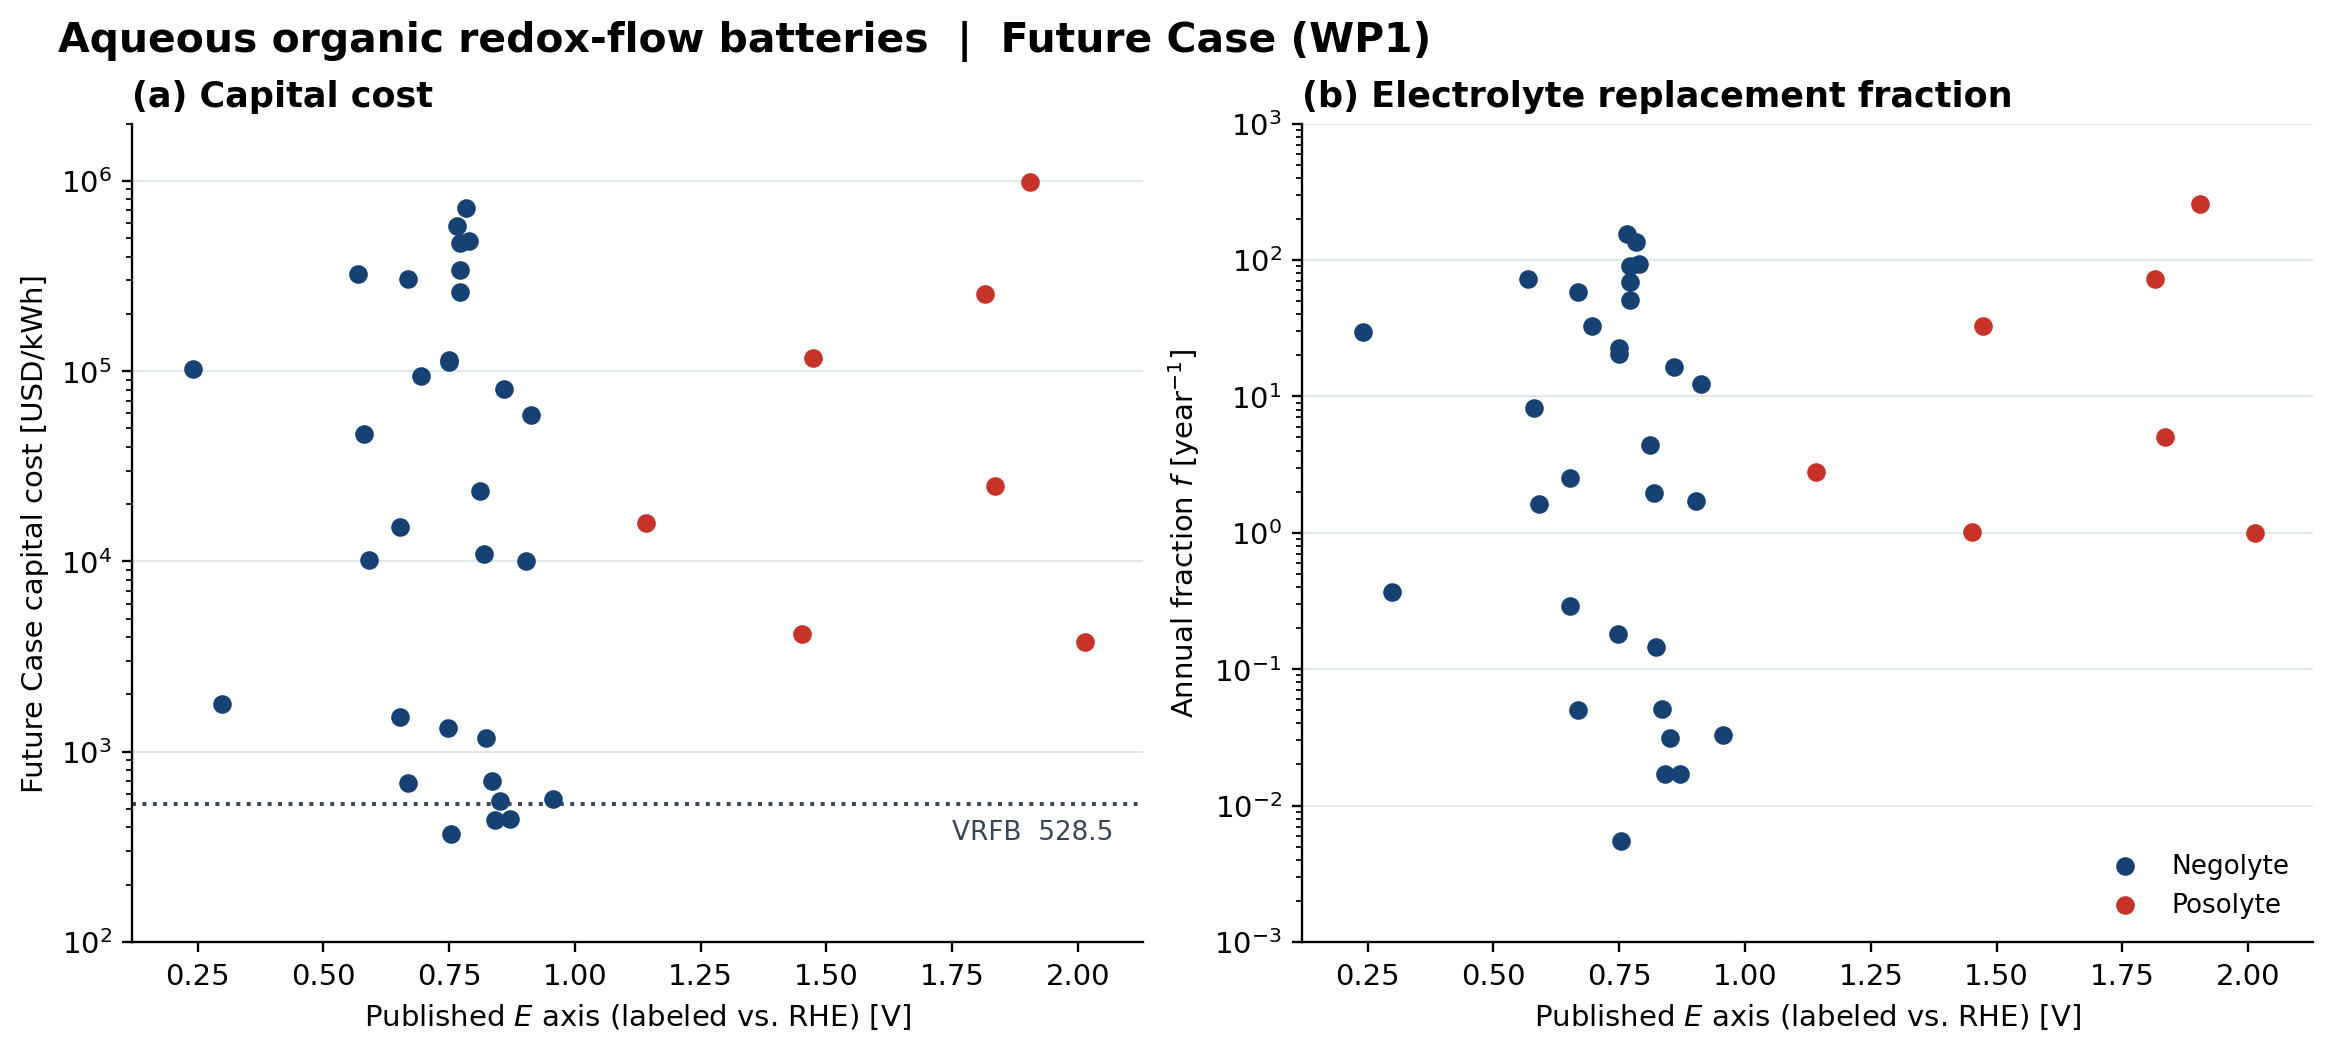

**Benchmark figure.** Reconstructed Emmel Fig. 2(a)–(b) with digitized potentials and published vertical coordinates.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.9), layout='constrained')
x_col = 'potential_fig2_digitized_V'
palette = {'negolyte':'#164273', 'posolyte':'#c73329'}
for ax, y_col in zip(axes, ['capital_usd_kWh','f_annual_table_S8']):
    ax.set_axisbelow(True)
    ax.grid(axis='y', which='major', color='#dfe6ed', linewidth=0.65)
    for role, color in palette.items():
        subset = emmel.loc[emmel.electrode_role.eq(role)]
        ax.scatter(subset[x_col], subset[y_col], s=29, color=color, label=role.capitalize(), zorder=3)
    ax.set_xlim(0.12, 2.13)
    ax.set_xticks(np.arange(0.25, 2.01, 0.25))
    ax.set_xlabel(r'Published $E$ axis (labeled vs. RHE) [V]')
    ax.set_yscale('log')
    ax.tick_params(direction='out', width=0.8)
    ax.spines[['top','right']].set_visible(False)

axes[0].set_title('(a) Capital cost', loc='left', fontweight='bold')
axes[0].set_ylabel('Future Case capital cost [USD/kWh]')
axes[0].set_ylim(100, 2e6)
axes[0].axhline(528.46, ls=':', lw=1.35, color='#3a4653', zorder=2)
axes[0].annotate('VRFB  528.5', (2.07, 528.46), xytext=(0, -12), textcoords='offset points',
                 ha='right', color='#3a4653', fontsize=9)
axes[1].set_title('(b) Electrolyte replacement fraction', loc='left', fontweight='bold')
axes[1].set_ylabel(r'Annual fraction $f$ [year$^{-1}$]')
axes[1].set_ylim(1e-3, 1e3)
axes[1].legend(frameon=False, loc='lower right', fontsize=9)
fig.suptitle('Aqueous organic redox-flow batteries  |  Future Case (WP1)',
             ha='left', x=0.02, fontsize=14, fontweight='bold')
assert [len(series.get_offsets()) for series in axes[0].collections] == [31, 7]
assert [len(series.get_offsets()) for series in axes[1].collections] == [31, 7]
fig.savefig(FIGURE_PATH, dpi=210, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(FIGURE_PATH)))
display(Markdown('**Benchmark figure.** Reconstructed Emmel Fig. 2(a)–(b) with digitized potentials and published vertical coordinates.'))

In [8]:
# Section 5. Yang hydroquinones
# 5.1. Cost comparison under common phosphate conditions
"""
Yang Fig. 1 provides the CV half-wave potentials. Section 2.2.1 and Fig. 2
give the common phosphate PS test. For O-3, use the PS daily rate in Table 1.
Yang and Navarro García et al. provide the solubilities and the polymorph data.
The ammonium ferrocyanide comparison uses Emmel's published Nafion case.

Active material is priced on a neutral-molecule mass basis at USD 3.48/kg.
The amines can protonate in solution. Acid is included in the carrier cost.
Procurement as a preformed salt would require a different mass and price basis.

The test concentration is 0.10 M in 1 M H3PO4. Eq. 5 uses saturation
solubility as an engineering scenario. Fade at saturation has not been measured
here. The extrapolation for fast-fading O-3 is a stress case. A shared 1.40 V
full-cell discharge voltage is a scenario near DHDMBS (published 1.39 V).
The Fig. 1 values are sulfate half-cell potentials vs Ag/AgCl. The stack
count uses the observed TEMPTMA/DHDMBS WP1 range and its midpoint.

Both maintenance variants annualize the Yang daily inputs directly. The
single-stack sensitivity uses S38's printed time index. The independent mode
replaces all stacks and discounts the first renewal at threshold crossing.
"""
from dataclasses import replace

display(Markdown('## 5. Yang hydroquinones: cost, inverse targets, and cycling protocol'))

yang_stage_inputs = pd.DataFrame(
    {
        'neutral_mass_g_mol': [251.33, 308.38, 336.43, 336.43],
        'e_per_mol': [2, 2, 2, 2],
        'ortho_sites_substituted': [4, 2, 4, 4],
        'E_half_V_vs_AgAgCl_sulfate': [0.54, 0.77, 0.64, 0.65],
        'solubility_M_phosphate': [0.48, 0.53, 0.40, 0.55],
        'fade_pct_day_phosphate_PS': [7.30, 52.70, 0.87, 0.45],
    },
    index=pd.Index(['O-1', 'O-3', 'O-5', 'asym-O-5'], name='molecule'),
)
yang_carriers = {
    'H3PO4': dict(carrier_kg_L=1.05, salt_mol_L=1, salt_g_mol=97.994, salt_usd_kg=0.50),
    'H2SO4': dict(carrier_kg_L=1.06, salt_mol_L=1, salt_g_mol=98.079, salt_usd_kg=0.17),
}
# Carrier densities and the H3PO4 price are scenario inputs. The H2SO4 price is from Table S9.
yang_organic_price_usd_kg = 3.48
yang_stack_price_usd = 993.82
yang_base_ud = 1.40
yang_stack_low, yang_stack_high = sorted(
    by_name.loc[['TEMPTMA', 'DHDMBS'], 'stacks'].astype(float)
)
yang_stack_mid = (yang_stack_low + yang_stack_high) / 2
yang_published_targets = {
    'ammonium ferrocyanide': 651.7, 'VRFB Future': 528.5, 'VRFB Present': 676.7,
}
yang_modes = {'sensitivity_variant': True, 'independent': False}


def yang_half_cell(molecule, acid, solubility_M):
    inputs = yang_stage_inputs.loc[molecule]
    return HalfCell(
        mass_g_mol=float(inputs.neutral_mass_g_mol),
        electrons=int(inputs.e_per_mol),
        active_mol_L=solubility_M,
        active_usd_kg=yang_organic_price_usd_kg,
        **yang_carriers[acid],
    )


def yang_fixed_cost_inputs(stacks, mode):
    total_power, pump = power_cost(stacks, yang_stack_price_usd)
    replacement_stacks = 1 if yang_modes[mode] else stacks
    replacement_usd_kW = (
        replacement_stacks * yang_stack_price_usd / SYSTEM_KW + INVERTER_USD_KW + pump
    )
    return total_power, replacement_usd_kW


def yang_cost(half_cell, fade_pct_day, mode, *, voltage=yang_base_ud, stacks=yang_stack_mid):
    power_usd_kW, replacement_usd_kW = yang_fixed_cost_inputs(stacks, mode)
    electrolyte = sum(eq5_electrolyte((half_cell, ideal_counter(half_cell)), voltage).values())
    maintenance, exchange_npv, stack_npv, n_exchanges = eq6_maintenance(
        electrolyte, fade_pct_day / 100 * 365, replacement_usd_kW,
        index_as_printed=yang_modes[mode],
    )
    return dict(
        eq5_usd_kWh=electrolyte, power_usd_kWh=power_usd_kW / DISCHARGE_H,
        exchange_npv_usd_kWh=exchange_npv, stack_npv_usd_kWh=stack_npv, n_exchanges=n_exchanges,
        capital_usd_kWh=eq1_capital(electrolyte, power_usd_kW, maintenance),
    )


yang_phosphate = {
    name: yang_half_cell(name, 'H3PO4', row.solubility_M_phosphate)
    for name, row in yang_stage_inputs.iterrows()
}
yang_comparison_rows = []
for mode in yang_modes:
    o3_fade = yang_stage_inputs.loc['O-3', 'fade_pct_day_phosphate_PS']
    o3_half = yang_phosphate['O-3']
    o3_base = yang_cost(o3_half, o3_fade, mode)['capital_usd_kWh']
    for name, side in yang_phosphate.items():
        fade = yang_stage_inputs.loc[name, 'fade_pct_day_phosphate_PS']
        base = yang_cost(side, fade, mode)
        total = base['capital_usd_kWh']
        yang_comparison_rows.append({
            'mode': mode, 'molecule': name, **base,
            'capital_low_stacks': yang_cost(side, fade, mode, stacks=yang_stack_low)['capital_usd_kWh'],
            'capital_high_stacks': yang_cost(side, fade, mode, stacks=yang_stack_high)['capital_usd_kWh'],
            'reduction_vs_O3_pct': 100 * (1 - total / o3_base),
            'fade_only_reduction_vs_O3_usd_kWh': o3_base - yang_cost(o3_half, fade, mode)['capital_usd_kWh'],
            **{f'gap_vs_{benchmark}': total - target for benchmark, target in yang_published_targets.items()},
        })
yang_comparison = pd.DataFrame(yang_comparison_rows).set_index(['mode', 'molecule'])
assert yang_comparison.capital_usd_kWh.between(
    yang_comparison.capital_low_stacks, yang_comparison.capital_high_stacks).all()
assert (yang_comparison.xs('O-3', level='molecule').reduction_vs_O3_pct == 0).all()

print(f'Stage 5 | Yang hydroquinones | U_d = {yang_base_ud:.2f} V, stacks {yang_stack_low:.2f}–{yang_stack_high:.2f}')
display(yang_stage_inputs)
display(Markdown('**Table 1.** Common-phosphate PS cost comparison at 1.40 V.'))
display(yang_comparison[[
    'eq5_usd_kWh', 'power_usd_kWh', 'exchange_npv_usd_kWh', 'stack_npv_usd_kWh', 'n_exchanges',
    'capital_usd_kWh', 'capital_low_stacks', 'capital_high_stacks',
]].round(2))
print('Comparison with incompletely substituted O-3 and published benchmark gaps. USD/kWh unless noted.')
display(yang_comparison[[
    'reduction_vs_O3_pct', 'fade_only_reduction_vs_O3_usd_kWh',
    'gap_vs_ammonium ferrocyanide', 'gap_vs_VRFB Future', 'gap_vs_VRFB Present',
]].round(2))

## 5. Yang hydroquinones: cost, inverse targets, and cycling protocol

Stage 5 | Yang hydroquinones | U_d = 1.40 V, stacks 430.17–438.64


,neutral_mass_g_mol,e_per_mol,ortho_sites_substituted,E_half_V_vs_AgAgCl_sulfate,solubility_M_phosphate,fade_pct_day_phosphate_PS
molecule,,,,,,
O-1,251.33,2,4,0.54,0.48,7.30
O-3,308.38,2,2,0.77,0.53,52.70
O-5,336.43,2,4,0.64,0.40,0.87
asym-O-5,336.43,2,4,0.65,0.55,0.45


**Table 1.** Common-phosphate PS cost comparison at 1.40 V.

eq5_usd_kWh  power_usd_kWh  exchange_npv_usd_kWh  stack_npv_usd_kWh  n_exchanges  capital_usd_kWh  capital_low_stacks  capital_high_stacks
mode                molecule                                                                                                                                            
sensitivity_variant O-1             75.61         248.07             166332.11              57.86         2664        166713.64           166711.80            166715.48
                    O-3             75.76         248.07            1203368.39              57.86        19235       1203750.08          1203748.24           1203751.92
                    O-5             88.37         248.07              23153.36              57.86          317         23547.65            23545.81             23549.50
                    asym-O-5        76.34         248.07              10352.78              57.86          164         10735.05            10733.20             10736.89
independent         O-1             75.61         248.07             166307.38             146.19         2664        166777.25           166774.55            166779.96
                    O-3             75.76         248.07            1203343.61             146.19        19235       1203813.64          1203810.94           1203816.35
                    O-5             88.37         248.07              23124.50             146.19          317         23607.13            23604.43             23609.84
                    asym-O-5        76.34         248.07              10327.85             146.19          164         10798.45            10795.74             10801.16

Comparison with incompletely substituted O-3 and published benchmark gaps. USD/kWh unless noted.


reduction_vs_O3_pct  fade_only_reduction_vs_O3_usd_kWh  gap_vs_ammonium ferrocyanide  gap_vs_VRFB Future  gap_vs_VRFB Present
mode                molecule                                                                                                                               
sensitivity_variant O-1                     86.15                         1036689.18                     166061.94           166185.14            166036.94
                    O-3                      0.00                               0.00                    1203098.38          1203221.58           1203073.38
                    O-5                     98.04                         1183518.00                      22895.95            23019.15             22870.95
                    asym-O-5                99.11                         1193093.21                      10083.35            10206.55             10058.35
independent         O-1                     86.15                         1036689.18                     166125.55           166248.75            166100.55
                    O-3                      0.00                               0.00                    1203161.94          1203285.14           1203136.94
                    O-5                     98.04                         1183517.96                      22955.43            23078.63             22930.43
                    asym-O-5                99.10                         1193093.18                      10146.75            10269.95             10121.75

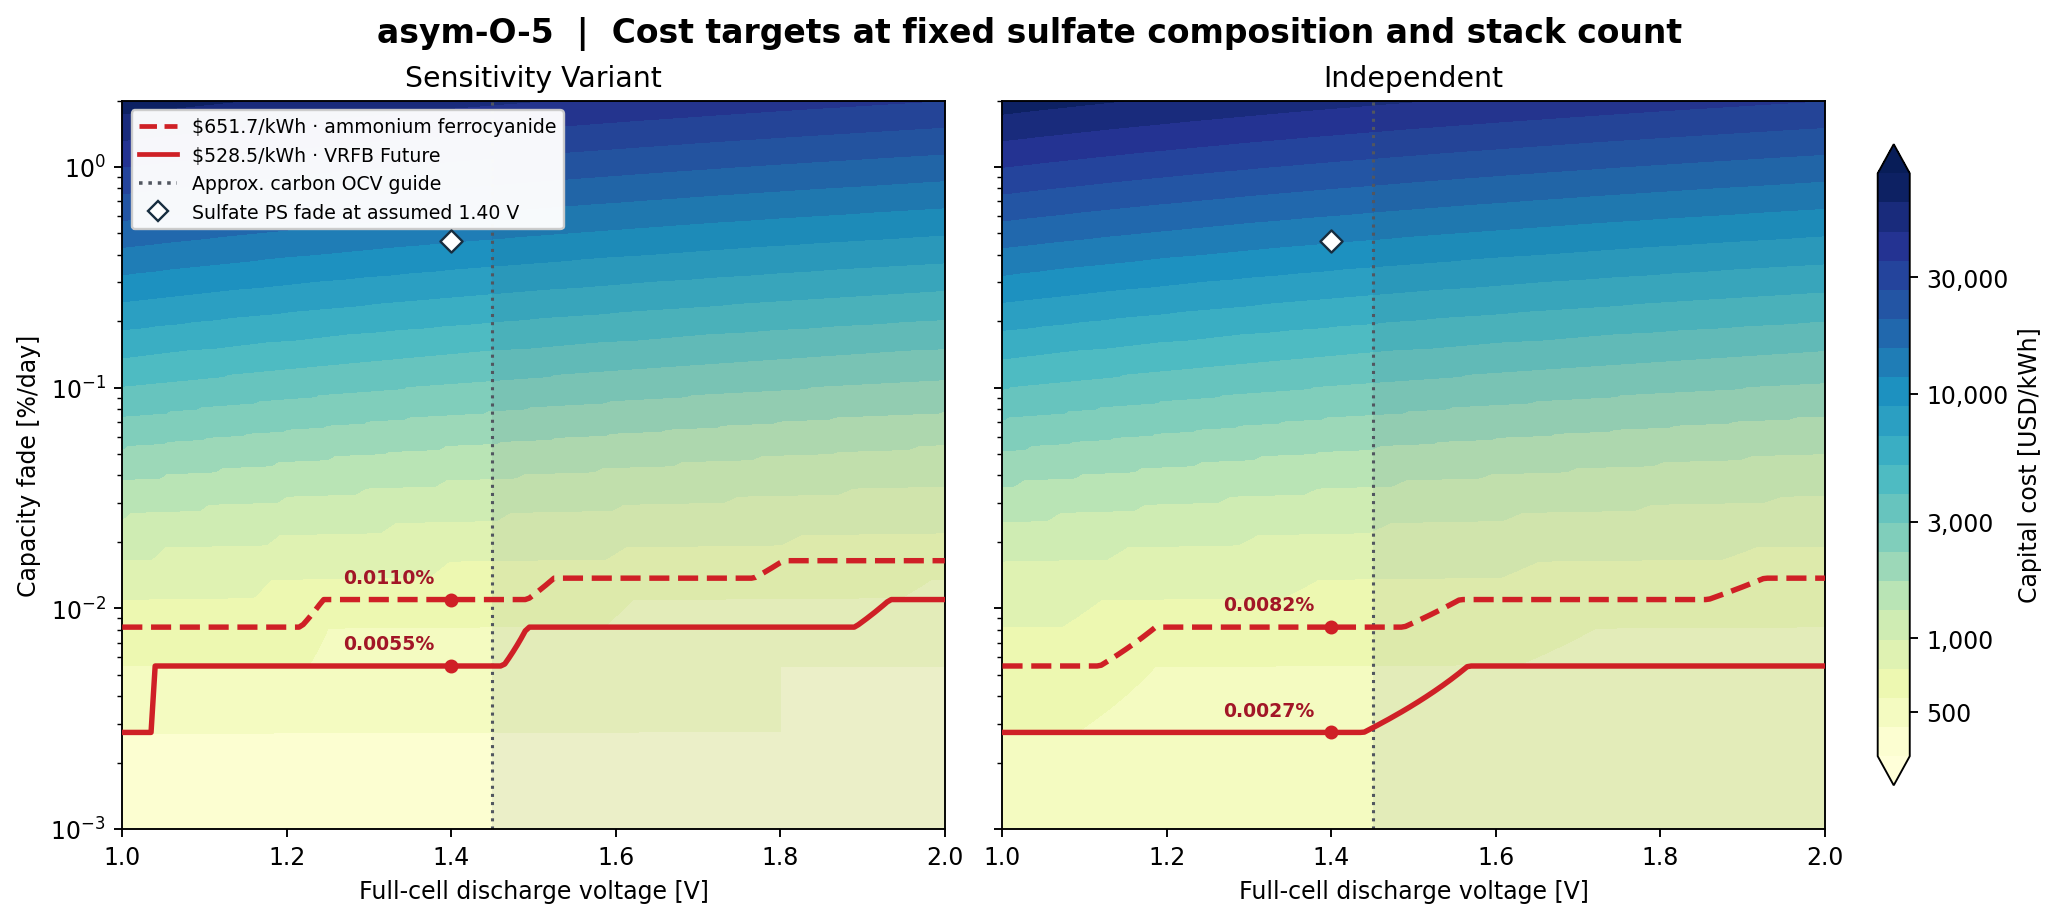

**Figure 1.** Inverse cost targets for asym-O-5 at fixed sulfate composition and stack count.

**Table 2.** Maximum daily fade (%/day). Voltages above the OCV guide are exploratory.

max_fade_pct_day  required_factor_vs_sulfate_PS
mode                benchmark             discharge_V                                                 
sensitivity_variant ammonium ferrocyanide 1.0                  0.008219                           56.0
                                          1.4                  0.010959                           42.0
                                          1.6                  0.013699                           33.6
                                          2.0                  0.016438                           28.0
                    VRFB Future           1.0                  0.002740                          167.9
                                          1.4                  0.005479                           84.0
                                          1.6                  0.008219                           56.0
                                          2.0                  0.010959                           42.0
independent         ammonium ferrocyanide 1.0                  0.005479                           84.0
                                          1.4                  0.008219                           56.0
                                          1.6                  0.010959                           42.0
                                          2.0                  0.013699                           33.6
                    VRFB Future           1.0                  0.002740                          167.9
                                          1.4                  0.002740                          167.9
                                          1.6                  0.005479                           84.0
                                          2.0                  0.005479                           84.0

Savings from matched 5% changes at the sulfate PS point. USD/kWh.


,base_usd_kWh,saving_5pct_lower_fade,saving_5pct_higher_voltage,unchanged_fade_at_2V
mode,,,,
sensitivity_variant,11787.66,549.80,546.75,8343.14
independent,11849.14,549.85,545.47,8412.67


In [9]:
# 5.2. Inverse cost targets for asym-O-5
"""
Use the sulfate scenario with solubility of 0.44 M and PS fade of 0.46%/day.
Sweep full-cell discharge voltage. The measured +0.65 V vs Ag/AgCl
is a half-cell value. The dotted line marks an approximate 1.45 V open-circuit
guide from the +0.20 V Ag/AgCl offset and the −0.60 V vs SHE carbon hydrogen
evolution bound at nominal pH 0. Voltages above the guide are exploratory.
The discrete replacement calculation yields an upper bound on eligible fade.
Use a rate strictly below the reported upper bound when setting targets.
"""
from io import BytesIO
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

asym_sulfate = yang_half_cell('asym-O-5', 'H2SO4', 0.44)
asym_ps_sulfate = float(yang.loc[
    (yang.source_table == 1) & (yang.molecule == 'asym-O-5') & (yang.method == 'PS'),
    'fade_pct_day',
].iloc[0])
carbon_ocv_guide = yang_stage_inputs.loc['asym-O-5', 'E_half_V_vs_AgAgCl_sulfate'] + 0.20 + 0.60
fade_grid = np.geomspace(0.001, 2.0, 360)
voltage_grid = np.linspace(1.0, 2.0, 201)
target_styles = {'ammonium ferrocyanide': '--', 'VRFB Future': '-'}
target_voltages = [1.0, yang_base_ud, 1.6, 2.0]

# Eq. 5 is proportional to 1/U_d at fixed composition. Eq. 6 is linear in the electrolyte
# cost for any fixed renewal schedule. Evaluating one factor per fade rate avoids a 2D Python loop.
asym_el_at_1V = sum(eq5_electrolyte((asym_sulfate, ideal_counter(asym_sulfate)), 1.0).values())


def asym_capital_grid(mode, voltages, fade_rates):
    power, replacement = yang_fixed_cost_inputs(yang_stack_mid, mode)
    maintenance = [
        eq6_maintenance(1.0, f / 100 * 365, replacement, index_as_printed=yang_modes[mode])
        for f in fade_rates
    ]
    exchange_multipliers = np.array([row[1] for row in maintenance])
    stack_npv = maintenance[0][2]
    electrolyte = asym_el_at_1V / np.asarray(voltages)
    return eq1_capital(electrolyte[None, :], power,
                       exchange_multipliers[:, None] * electrolyte[None, :] + stack_npv)


def max_fade_for_cost(target, voltage, mode):
    # Cost is nondecreasing with fade, including jumps when another exchange is triggered.
    lower, upper = 0.0, float(fade_grid[-1])
    if yang_cost(asym_sulfate, lower, mode, voltage=voltage)['capital_usd_kWh'] > target:
        return np.nan
    assert yang_cost(asym_sulfate, upper, mode, voltage=voltage)['capital_usd_kWh'] > target
    for _ in range(35):
        middle = (lower + upper) / 2
        if yang_cost(asym_sulfate, middle, mode, voltage=voltage)['capital_usd_kWh'] <= target:
            lower = middle
        else:
            upper = middle
    return lower


yang_limit_rows, yang_lever_rows = [], []
cost_levels = np.geomspace(330, 80000, 21)
cost_color = LogNorm(vmin=cost_levels[0], vmax=cost_levels[-1])
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3), sharey=True, layout='constrained')
for ax, mode in zip(axes, yang_modes):
    capital_grid = asym_capital_grid(mode, voltage_grid, fade_grid)
    assert (np.diff(capital_grid, axis=0) >= -1e-9).all()
    assert (np.diff(capital_grid, axis=1) < 0).all()
    assert np.isclose(capital_grid[110, 98], yang_cost(
        asym_sulfate, fade_grid[110], mode, voltage=voltage_grid[98])['capital_usd_kWh'])
    filled = ax.contourf(voltage_grid, fade_grid, capital_grid, levels=cost_levels,
                         norm=cost_color, cmap='YlGnBu', extend='both')
    for benchmark, linestyle in target_styles.items():
        target = yang_published_targets[benchmark]
        limits = np.array([max_fade_for_cost(target, voltage, mode) for voltage in voltage_grid])
        visible = np.isfinite(limits) & (limits >= fade_grid[0]) & (limits <= fade_grid[-1])
        ax.plot(voltage_grid, np.where(visible, limits, np.nan), linestyle=linestyle,
                color='#cf2026', linewidth=2.3, zorder=5)
        base_limit = max_fade_for_cost(target, yang_base_ud, mode)
        if np.isfinite(base_limit) and base_limit >= fade_grid[0]:
            ax.scatter(yang_base_ud, base_limit, color='#cf2026', s=24, zorder=6)
            ax.annotate(f'{base_limit:.4f}%', (yang_base_ud, base_limit),
                        xytext=(-7, 7), textcoords='offset points', ha='right',
                        fontsize=8, fontweight='bold', color='#a21627')
        for voltage in target_voltages:
            limit = max_fade_for_cost(target, voltage, mode)
            yang_limit_rows.append({
                'mode': mode, 'benchmark': benchmark, 'discharge_V': voltage,
                'max_fade_pct_day': limit,
                'required_factor_vs_sulfate_PS': asym_ps_sulfate / limit if limit > 0 else np.nan,
            })
            if np.isfinite(limit):
                attained = yang_cost(asym_sulfate, limit, mode, voltage=voltage)['capital_usd_kWh']
                above = yang_cost(asym_sulfate, limit + 1e-8, mode, voltage=voltage)['capital_usd_kWh']
                assert attained <= target < above

    base = yang_cost(asym_sulfate, asym_ps_sulfate, mode)['capital_usd_kWh']
    lower_fade = yang_cost(asym_sulfate, 0.95 * asym_ps_sulfate, mode)['capital_usd_kWh']
    higher_voltage = yang_cost(asym_sulfate, asym_ps_sulfate, mode,
                               voltage=1.05 * yang_base_ud)['capital_usd_kWh']
    best_voltage_only = yang_cost(asym_sulfate, asym_ps_sulfate, mode, voltage=2.0)['capital_usd_kWh']
    yang_lever_rows.append({
        'mode': mode, 'base_usd_kWh': base, 'saving_5pct_lower_fade': base - lower_fade,
        'saving_5pct_higher_voltage': base - higher_voltage, 'unchanged_fade_at_2V': best_voltage_only,
    })
    ax.axvspan(carbon_ocv_guide, 2.0, facecolor='#274766', alpha=.08)
    ax.axvline(carbon_ocv_guide, linestyle=':', color='#515660', linewidth=1.3)
    ax.scatter(yang_base_ud, asym_ps_sulfate, marker='D', s=44,
               facecolor='white', edgecolor='#172d3f', zorder=6)
    ax.set(yscale='log', xlim=(1, 2), ylim=(0.001, 2.0),
           xlabel='Full-cell discharge voltage [V]',
           title=mode.replace('_', ' ').title())
axes[0].set_ylabel('Capacity fade [%/day]')
handles = [
    Line2D([0], [0], color='#cf2026', linestyle=style, lw=2,
           label=f'${yang_published_targets[benchmark]:g}/kWh · {benchmark}')
    for benchmark, style in target_styles.items()
]
handles.extend([
    Line2D([0], [0], color='#515660', linestyle=':', label='Approx. carbon OCV guide'),
    Line2D([0], [0], marker='D', color='none', markeredgecolor='#172d3f',
           markerfacecolor='white', label='Sulfate PS fade at assumed 1.40 V'),
])
axes[0].legend(handles=handles, loc='upper left', fontsize=8, framealpha=.97)
colorbar = fig.colorbar(filled, ax=axes, shrink=.88, pad=.02)
colorbar.set_ticks([500, 1000, 3000, 10000, 30000])
colorbar.set_ticklabels(['500', '1,000', '3,000', '10,000', '30,000'])
colorbar.set_label('Capital cost [USD/kWh]')
fig.suptitle('asym-O-5  |  Cost targets at fixed sulfate composition and stack count',
             fontsize=14, fontweight='bold')


def show_yang_figure(figure, filename):
    with BytesIO() as buffer:
        figure.savefig(buffer, format='png', dpi=170, bbox_inches='tight', facecolor='white')
        figure_data = buffer.getvalue()
    (FIGURE_DIR / filename).write_bytes(figure_data)
    display(Image(data=figure_data))
    plt.close(figure)


show_yang_figure(fig, 'asym_o5_cost_contours.png')
display(Markdown('**Figure 1.** Inverse cost targets for asym-O-5 at fixed sulfate composition and stack count.'))
yang_limits = pd.DataFrame(yang_limit_rows).set_index(['mode', 'benchmark', 'discharge_V'])
yang_levers = pd.DataFrame(yang_lever_rows).set_index('mode')
display(Markdown('**Table 2.** Maximum daily fade (%/day). Voltages above the OCV guide are exploratory.'))
display(yang_limits.round({'max_fade_pct_day':6, 'required_factor_vs_sulfate_PS':1}))
print('Savings from matched 5% changes at the sulfate PS point. USD/kWh.')
display(yang_levers.round(2))

**Table 3.** Protocol and polymorph sensitivity. The PS and GS inputs come from Yang Table 1.

acid  PS_test_M  GS_test_M  PS_fade_pct_day  GS_fade_pct_day  PS_usd_kWh  GS_usd_kWh  GS_minus_PS_usd_kWh  same_acid_and_initial_M
mode                molecule                                                                                                                                     
sensitivity_variant O-1       H2SO4       0.10       0.05             5.70              2.9   127221.14    64906.82            -62314.32                    False
                    O-3       H3PO4       0.10       0.10            52.70             48.5  1203750.08  1107844.91            -95905.17                     True
                    O-5       H2SO4       0.05       0.08             0.78              1.1    27380.33    38470.68             11090.34                    False
                    asym-O-5  H2SO4       0.10       0.10             0.46              1.8    11787.66    45150.77             33363.12                     True
independent         O-1       H2SO4       0.10       0.05             5.70              2.9   127285.33    64971.01            -62314.31                    False
                    O-3       H3PO4       0.10       0.10            52.70             48.5  1203813.64  1107908.47            -95905.17                     True
                    O-5       H2SO4       0.05       0.08             0.78              1.1    27431.19    38521.50             11090.31                    False
                    asym-O-5  H2SO4       0.10       0.10             0.46              1.8    11849.14    45212.13             33363.00                     True

O-5 polymorph | fixed fade, sulfate solubility 0.24 M → 0.06 M.


held_fade_pct_day  fresh_eq5_usd_kWh  aged_eq5_usd_kWh  fresh_total_usd_kWh  aged_total_usd_kWh  aged_minus_fresh_usd_kWh
mode                fade_input_method                                                                                                                           
sensitivity_variant PS                              0.78             114.83            328.31             27380.33            77712.96                  50332.63
                    GS                              1.10             114.83            328.31             38470.68           109420.79                  70950.11
independent         PS                              0.78             114.83            328.31             27431.19            77694.15                  50262.96
                    GS                              1.10             114.83            328.31             38521.50           109401.87                  70880.37

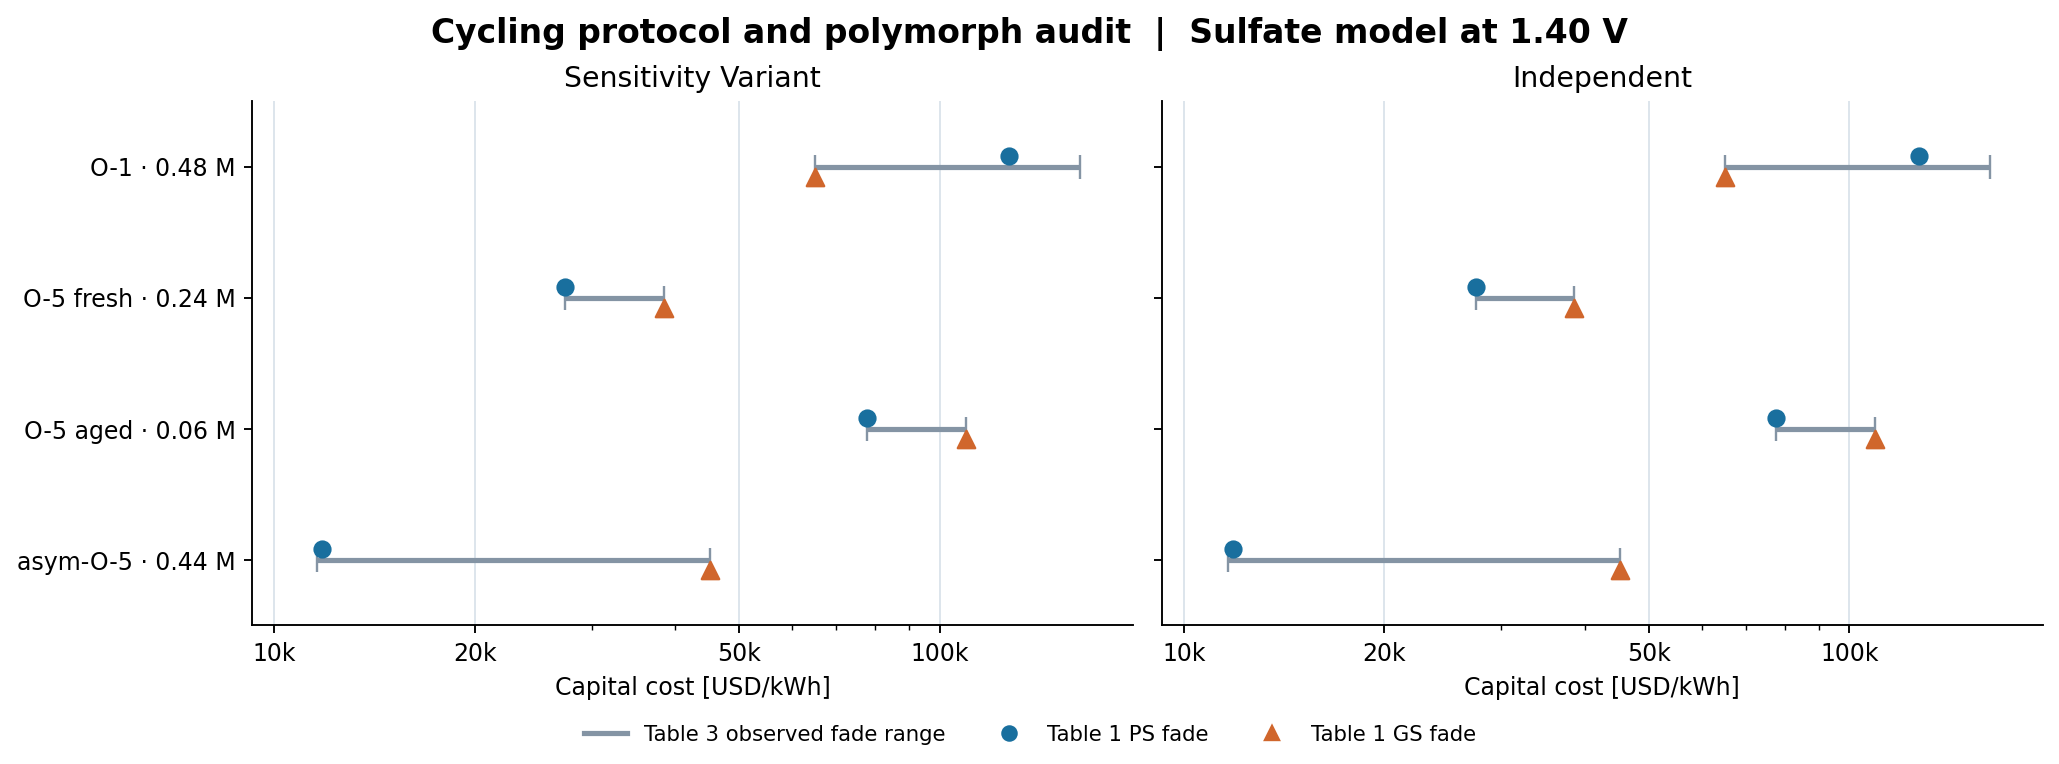

**Figure 2.** Protocol markers and observed fade intervals translated into sulfate scenario costs.

low_fade_pct_day  high_fade_pct_day  cost_low_usd_kWh  cost_high_usd_kWh  range_width_usd_kWh
mode                case                                                                                                             
sensitivity_variant O-1 · 0.48 M                    2.90                7.3          64906.82          162829.32             97922.50
                    O-5 fresh · 0.24 M              0.78                1.1          27380.33           38470.68             11090.34
                    O-5 aged · 0.06 M               0.78                1.1          77712.96          109420.79             31707.82
                    asym-O-5 · 0.44 M               0.45                1.8          11575.23           45150.77             33575.55
independent         O-1 · 0.48 M                    2.90                7.3          64971.01          162893.51             97922.50
                    O-5 fresh · 0.24 M              0.78                1.1          27431.19           38521.50             11090.31
                    O-5 aged · 0.06 M               0.78                1.1          77694.15          109401.87             31707.72
                    asym-O-5 · 0.44 M               0.45                1.8          11636.62           45212.13             33575.51

In [10]:
# 5.3. Cycling protocol and polymorph audit
"""
Substitute PS and GS fade into the same cost scenario for each material.
Asym-O-5 matches starting concentration and acid across protocols (0.10 M,
1 M H2SO4). SOC and temperature can still differ. O-1 and O-5 also change
test concentration. O-3 is a rapid-fade stress case with matched formulation.
Table 3 bars propagate observed fade ranges, including other conditions.

For O-5 keep fade fixed while changing sulfate solubility from 0.24 M to
0.06 M. The aged solubility is below the original GS concentration (0.075 M),
so coupling aged solubility with GS fade is counterfactual. The 0.48 M O-1
sulfate value is assigned to Navarro García's MMHQ entry based on the
reported m/z 252, nine methyl protons, and Yang's O-1 structure.
"""
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

yang_audit_sides = {
    'O-1': yang_half_cell('O-1', 'H2SO4', 0.48),
    'O-3': yang_phosphate['O-3'],
    'O-5': yang_half_cell('O-5', 'H2SO4', 0.24),
    'asym-O-5': asym_sulfate,
}
o5_aged = replace(yang_audit_sides['O-5'], active_mol_L=0.06)
yang_table1 = yang.loc[yang.source_table == 1].set_index(['molecule', 'method'])
yang_table3 = yang.loc[yang.source_table == 3].set_index('molecule')
protocol_rows, polymorph_rows = [], []
for mode in yang_modes:
    for name, side in yang_audit_sides.items():
        gs = yang_table1.loc[(name, 'GS')]
        ps = yang_table1.loc[(name, 'PS')]
        gs_total = yang_cost(side, gs.fade_pct_day, mode)['capital_usd_kWh']
        ps_total = yang_cost(side, ps.fade_pct_day, mode)['capital_usd_kWh']
        protocol_rows.append({
            'mode': mode, 'molecule': name, 'acid': ps.electrolyte,
            'PS_test_M': ps.active_conc_mol_L, 'GS_test_M': gs.active_conc_mol_L,
            'PS_fade_pct_day': ps.fade_pct_day, 'GS_fade_pct_day': gs.fade_pct_day,
            'PS_usd_kWh': ps_total, 'GS_usd_kWh': gs_total, 'GS_minus_PS_usd_kWh': gs_total - ps_total,
            'same_acid_and_initial_M': (
                gs.electrolyte == ps.electrolyte and gs.active_conc_mol_L == ps.active_conc_mol_L
            ),
        })
    for method in ['PS', 'GS']:
        fade = yang_table1.loc[('O-5', method), 'fade_pct_day']
        fresh = yang_cost(yang_audit_sides['O-5'], fade, mode)
        aged = yang_cost(o5_aged, fade, mode)
        polymorph_rows.append({
            'mode': mode, 'fade_input_method': method, 'held_fade_pct_day': fade,
            'fresh_eq5_usd_kWh': fresh['eq5_usd_kWh'], 'aged_eq5_usd_kWh': aged['eq5_usd_kWh'],
            'fresh_total_usd_kWh': fresh['capital_usd_kWh'], 'aged_total_usd_kWh': aged['capital_usd_kWh'],
            'aged_minus_fresh_usd_kWh': aged['capital_usd_kWh'] - fresh['capital_usd_kWh'],
        })

yang_protocol_audit = pd.DataFrame(protocol_rows).set_index(['mode', 'molecule'])
yang_polymorph_audit = pd.DataFrame(polymorph_rows).set_index(['mode', 'fade_input_method'])
assert yang_protocol_audit.xs('asym-O-5', level='molecule').same_acid_and_initial_M.all()
assert (~yang_protocol_audit.xs('O-5', level='molecule').same_acid_and_initial_M).all()
assert (yang_polymorph_audit.aged_minus_fresh_usd_kWh > 0).all()
display(Markdown('**Table 3.** Protocol and polymorph sensitivity. The PS and GS inputs come from Yang Table 1.'))
display(yang_protocol_audit.round(2))
print('O-5 polymorph | fixed fade, sulfate solubility 0.24 M → 0.06 M.')
display(yang_polymorph_audit.round(2))

audit_cases = [
    ('O-1 · 0.48 M', 'O-1', yang_audit_sides['O-1']),
    ('O-5 fresh · 0.24 M', 'O-5', yang_audit_sides['O-5']),
    ('O-5 aged · 0.06 M', 'O-5', o5_aged),
    ('asym-O-5 · 0.44 M', 'asym-O-5', asym_sulfate),
]
range_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True, layout='constrained')
for ax, mode in zip(axes, yang_modes):
    for row_index, (label, name, side) in enumerate(audit_cases):
        rates = yang_table3.loc[name]
        lower, upper = (
            yang_cost(side, fade, mode)['capital_usd_kWh']
            for fade in [rates.fade_range_min_pct_day, rates.fade_range_max_pct_day]
        )
        ps_total, gs_total = (
            yang_cost(side, yang_table1.loc[(name, method), 'fade_pct_day'], mode)['capital_usd_kWh']
            for method in ['PS', 'GS']
        )
        range_rows.append({
            'mode': mode, 'case': label, 'low_fade_pct_day': rates.fade_range_min_pct_day,
            'high_fade_pct_day': rates.fade_range_max_pct_day, 'cost_low_usd_kWh': lower,
            'cost_high_usd_kWh': upper, 'range_width_usd_kWh': upper - lower,
        })
        assert lower - 1e-7 <= min(ps_total, gs_total) <= max(ps_total, gs_total) <= upper + 1e-7
        ax.errorbar((upper + lower) / 2, row_index, xerr=(upper - lower) / 2,
                    fmt='none', color='#8494a4', elinewidth=2.2, capsize=5, zorder=2)
        ax.scatter(ps_total, row_index-.08, marker='o', color='#196f9e', s=45, zorder=4)
        ax.scatter(gs_total, row_index+.08, marker='^', color='#d0662c', s=54, zorder=4)
    ax.set(xscale='log', xlabel='Capital cost [USD/kWh]', title=mode.replace('_', ' ').title())
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1000:g}k'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(axis='x', which='major', color='#dce4eb', linewidth=.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_yticks(range(len(audit_cases)), [row[0] for row in audit_cases])
axes[0].set_ylim(len(audit_cases)-.5, -.5)
yang_fade_range_audit = pd.DataFrame(range_rows).set_index(['mode', 'case'])
axes[0].set_xlim(0.8 * yang_fade_range_audit.cost_low_usd_kWh.min(),
                 1.2 * yang_fade_range_audit.cost_high_usd_kWh.max())
legend = [
    Line2D([0], [0], color='#8494a4', lw=2.2, label='Table 3 observed fade range'),
    Line2D([0], [0], color='#196f9e', marker='o', linestyle='none', label='Table 1 PS fade'),
    Line2D([0], [0], color='#d0662c', marker='^', linestyle='none', label='Table 1 GS fade'),
]
fig.legend(handles=legend, fontsize=9, loc='outside lower center', ncol=3, frameon=False)
fig.suptitle('Cycling protocol and polymorph audit  |  Sulfate model at 1.40 V',
             fontsize=14, fontweight='bold')
show_yang_figure(fig, 'protocol_polymorph_audit.png')
display(Markdown('**Figure 2.** Protocol markers and observed fade intervals translated into sulfate scenario costs.'))
display(yang_fade_range_audit.round(2))